Library

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_curve, auc

Data Info

In [2]:
heart_df = pd.read_csv('heart_disease_dataset.csv')
heart_df.head(20)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0
5,56,1,2,120,236,0,0,178,0,0.8,1,0,3,0
6,62,0,4,140,268,0,2,160,0,3.6,3,2,3,1
7,57,0,4,120,354,0,0,163,1,0.6,1,0,3,0
8,63,1,4,130,254,0,2,147,0,1.4,2,1,7,1
9,53,1,4,140,203,1,2,155,1,3.1,3,0,7,1


In [35]:
heart_df.shape

(303, 14)

In [4]:
heart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  num       303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:
heart_df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

In [6]:
heart_df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,-1319.468647,-655.363036,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,11432.566205,8111.366638,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,-100000.000000,-100000.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


In [7]:
heart_df['num'].value_counts()

num
0    164
1    139
Name: count, dtype: int64

In [8]:
heart_df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')

Visualization

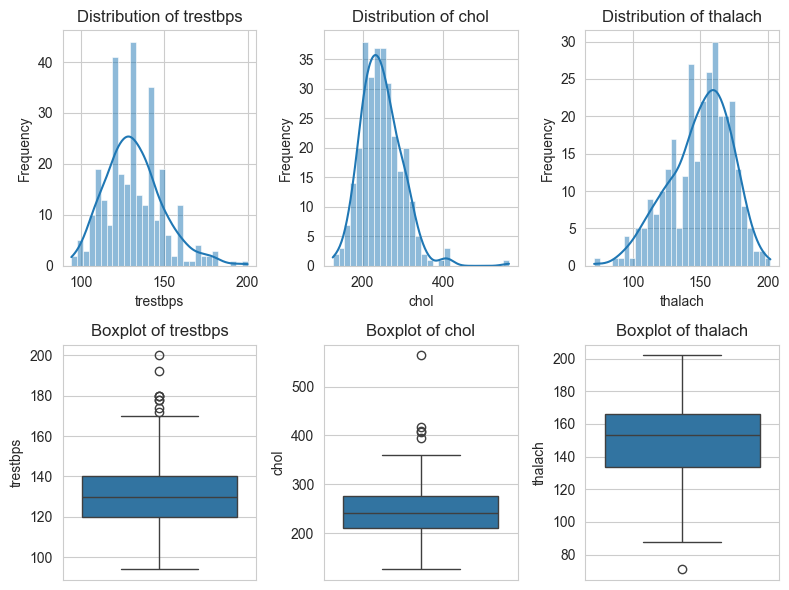

In [23]:
sns.set_style('whitegrid')

plt.figure(figsize=(8, 6))

features = ['trestbps', 'chol', 'thalach']

# subplots for each numerical column
for i, feature in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.histplot(heart_df[feature], bins=30, kde=True)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    
# boxplots for outliers
for i, feature in enumerate(features, i):
    plt.subplot(2,3, i+1)
    sns.boxplot(y=heart_df[feature])
    plt.title(f'Boxplot of {feature}')
    
plt.tight_layout()
plt.show()

In [12]:
heart_df['sex'].value_counts()

sex
1    206
0     97
Name: count, dtype: int64

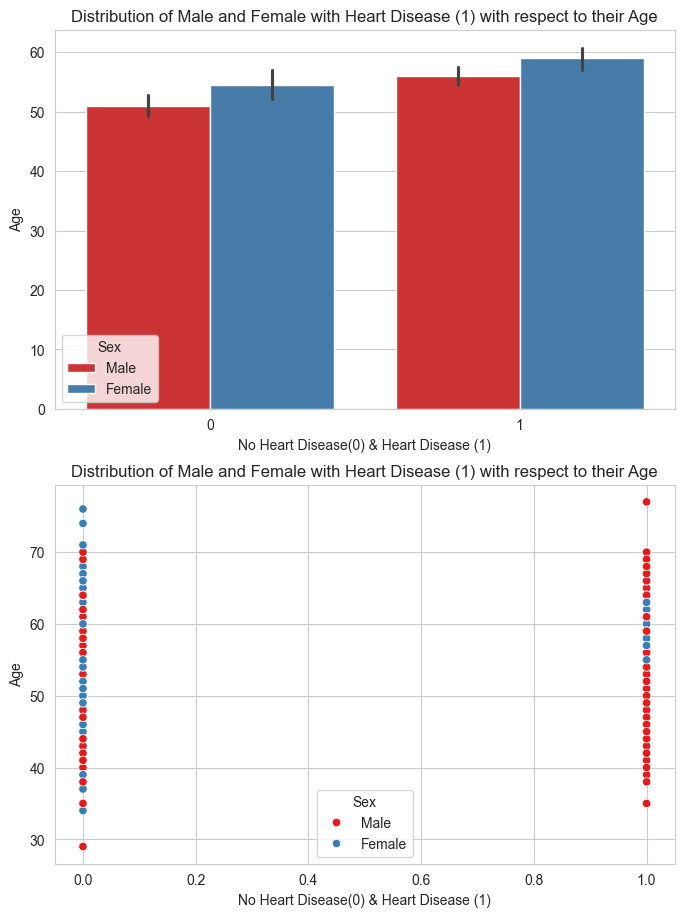

In [13]:
sns.set_style('whitegrid')

fig, axes = plt.subplots(2, 1, figsize=(8, 6))

heart_df_copy = pd.DataFrame(heart_df).copy()

heart_df_copy['sex'] = heart_df_copy['sex'].map({1: 'Male', 0: 'Female'})

sns.barplot(x='num', y='age', hue='sex', data=heart_df_copy, palette='Set1', ax=axes[0])
axes[0].set_title('Distribution of Male and Female with Heart Disease (1) with respect to their Age')
axes[0].set_xlabel('No Heart Disease(0) & Heart Disease (1)')
axes[0].set_ylabel('Age')
axes[0].legend(title='Sex')

sns.scatterplot(x='num', y='age', hue='sex', data=heart_df_copy, palette='Set1', ax=axes[1])
axes[1].set_title('Distribution of Male and Female with Heart Disease (1) with respect to their Age')
axes[1].set_xlabel('No Heart Disease(0) & Heart Disease (1)')
axes[1].set_ylabel('Age')
axes[1].legend(title='Sex')

plt.subplots_adjust(top=1.5)

plt.show()

Model train & test

In [14]:
X = heart_df.drop(['num', 'age', 'sex'], axis=1)
y = heart_df.num
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)

In [16]:
print(X_train.shape)
print(X_test.shape)

(242, 11)
(61, 11)


In [17]:
print(y_train.shape)
print(y_test.shape)

(242,)
(61,)


Decision Tree

In [19]:
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)

DecisionTreeClassifier()

In [21]:
dt_X_train_pred = dt_model.predict(X_train)
dt_train_accuracy = accuracy_score(dt_X_train_pred, y_train)

print("Accuracy for Training set: ", dt_train_accuracy)

Accuracy for Training set:  1.0


In [22]:
dt_X_test_pred = dt_model.predict(X_test)
dt_test_accuracy = accuracy_score(dt_X_test_pred, y_test)

print("Accuracy for Testing set: ", dt_test_accuracy)

Accuracy for Testing set:  0.6721311475409836


In [24]:
y_pred = dt_model.predict(X)

report = classification_report(y_pred, y)
print(report)

              precision    recall  f1-score   support

           0       0.95      0.93      0.94       168
           1       0.91      0.94      0.93       135

    accuracy                           0.93       303
   macro avg       0.93      0.93      0.93       303
weighted avg       0.93      0.93      0.93       303



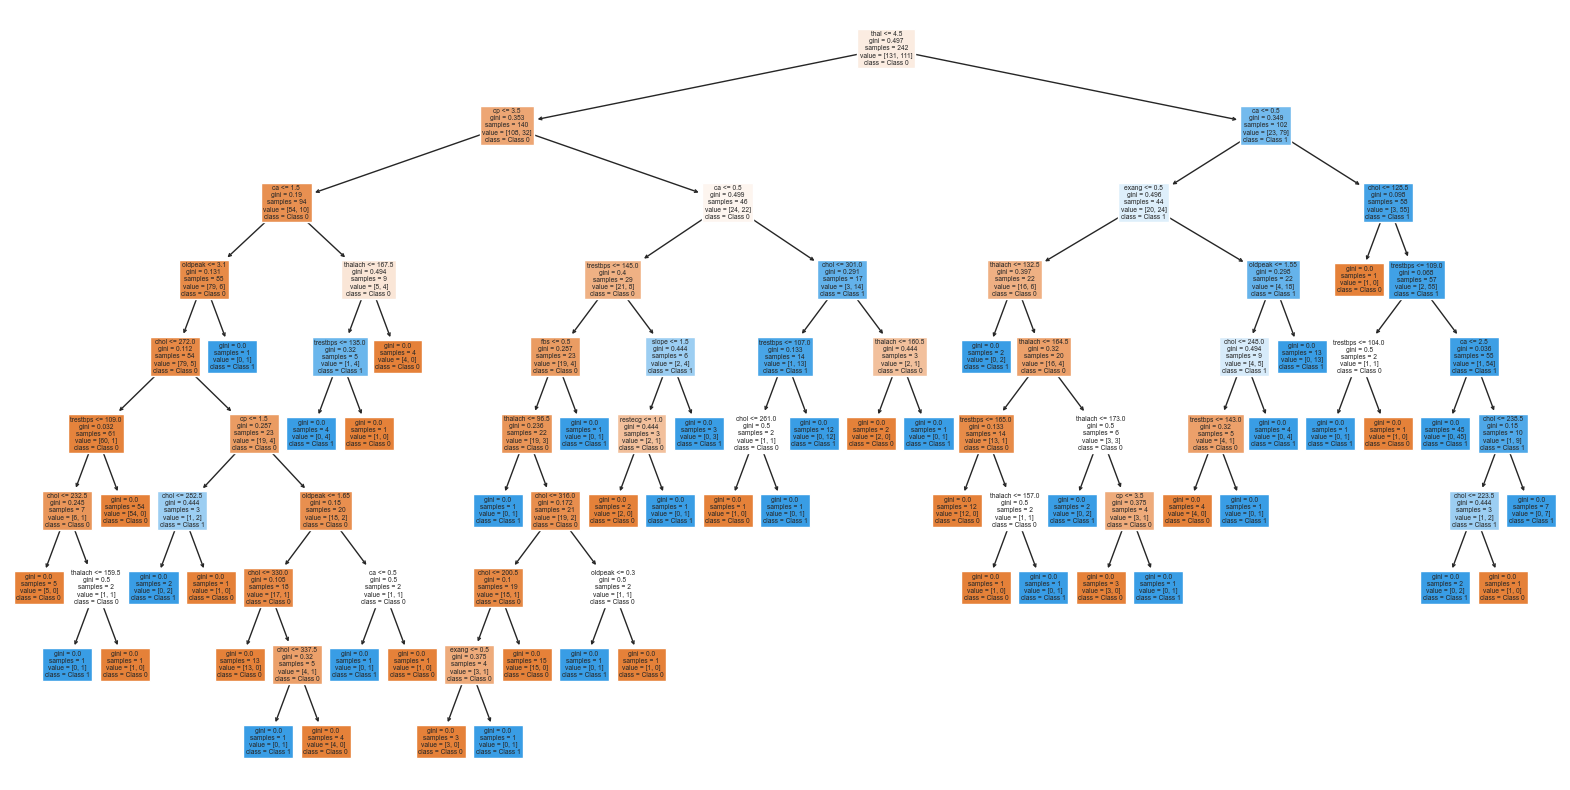

In [25]:
plt.figure(figsize=(20,10))
plot_tree(dt_model, filled=True, feature_names=X.columns, class_names=['Class 0', 'Class 1'])
plt.show()

Test new data

In [26]:
X.columns

Index(['cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang',
       'oldpeak', 'slope', 'ca', 'thal'],
      dtype='object')

In [27]:
new_data = {
    'cp': [2, 2, 3, 1, 0],
    'trestbps': [150, 174, 162, 103, 90],
    'chol': [120, 570, 345, 600, 100],
    'fbs': [1, 0, 1, 1, 0],
    'restecg': [2, 2, 1, 0, 1],
    'thalach': [205, 70, 65, 83, 210],
    'exang': [1, 0, 1, 1, 1],
    'oldpeak': [0.0, 2.6, 6.5, 7.0, 1.7],
    'slope': [2, 0, 1, 2, 1],
    'ca': [3, 2, 0, 1, 1],
    'thal': [2, 3, 3, 2, 0]
}


new_heart_df = pd.DataFrame(new_data)
new_heart_df

,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,2,150,120,1,2,205,1,0.0,2,3,2
1,2,174,570,0,2,70,0,2.6,0,2,3
2,3,162,345,1,1,65,1,6.5,1,0,3
3,1,103,600,1,0,83,1,7.0,2,1,2
4,0,90,100,0,1,210,1,1.7,1,1,0


In [28]:
new_data_pred = dt_model.predict(new_heart_df)

In [29]:
new_heart_df['num'] = new_data_pred

In [30]:
new_heart_df

,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,2,150,120,1,2,205,1,0.0,2,3,2,0
1,2,174,570,0,2,70,0,2.6,0,2,3,0
2,3,162,345,1,1,65,1,6.5,1,0,3,1
3,1,103,600,1,0,83,1,7.0,2,1,2,1
4,0,90,100,0,1,210,1,1.7,1,1,0,0


Naive Bayes

In [31]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

GaussianNB()

In [32]:
nb_y_test_pred = nb_model.predict(X_test)

In [33]:
nb_test_accuracy = accuracy_score(nb_y_test_pred, y_test)
print("Accuracy for Naive Bayes: ", nb_test_accuracy)

Accuracy for Naive Bayes:  0.4426229508196721


In [39]:
from sklearn.metrics import classification_report

nb_y_pred = nb_model.predict(X)

nb_report = classification_report(y, nb_y_pred)
print(nb_report)

              precision    recall  f1-score   support

           0       0.75      0.02      0.04       164
           1       0.46      0.99      0.63       139

    accuracy                           0.47       303
   macro avg       0.61      0.51      0.33       303
weighted avg       0.62      0.47      0.31       303



ROC Curve

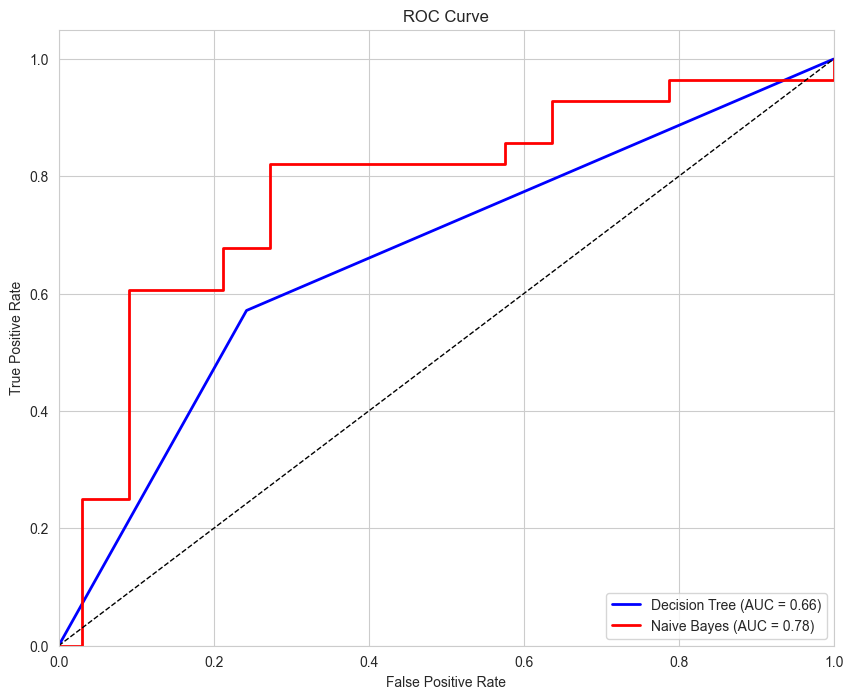

In [34]:
# ROC curve for Decision Tree 
dt_y_test_pred_proba = dt_model.predict_proba(X_test)[:, 1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_y_test_pred_proba)
roc_auc_dt = auc(fpr_dt, tpr_dt)

# ROC curve for Naive Bayes 
nb_y_test_pred_proba = nb_model.predict_proba(X_test)[:, 1]
fpr_nb, tpr_nb, _ = roc_curve(y_test, nb_y_test_pred_proba)
roc_auc_nb = auc(fpr_nb, tpr_nb)

plt.figure(figsize=(10, 8))
plt.plot(fpr_dt, tpr_dt, color='blue', lw=2, label='Decision Tree (AUC = %0.2f)' % roc_auc_dt)
plt.plot(fpr_nb, tpr_nb, color='red', lw=2, label='Naive Bayes (AUC = %0.2f)' % roc_auc_nb)
plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()